# 19 売上ゼロの内訳と販売機会

学習期間の全行を、カタログ期間、コラボ企画の対象店舗、売上金額で分類する。条件上販売可能なゼロは「その日・店舗・商品に記録された売上が0円」という意味であり、欠品や需要ゼロの理由は特定できない。

販売計画の条件は資料に基づいて再構築し、2022〜2024年の整合性を検査する。将来の売上・来店・当日売上順位は未知であり、以下の事後分析をそのまま未来の同日特徴量に用いない。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'input').is_dir():ROOT=ROOT.parent
assert (ROOT/'input').is_dir()
INPUT=ROOT/'input';sns.set_theme(style='whitegrid');pd.set_option('display.max_columns',50);pd.options.display.float_format='{:,.4f}'.format
train=pd.read_csv(INPUT/'train.csv',parse_dates=['date'])
menus=pd.read_csv(INPUT/'menus.csv')[['item_id','item_name','category','menu_type']]
stores=pd.read_csv(INPUT/'stores.csv')[['store_id','area_type']];store_ids=stores.store_id.tolist()
calendar=pd.read_csv(INPUT/'calendar.csv',parse_dates=['date'])[['date','is_holiday']]
catalog=pd.read_csv(INPUT/'menu_catalog_history.csv',parse_dates=['effective_start_date','effective_end_date'])
catalog['date']=[pd.date_range(a,b) for a,b in zip(catalog.effective_start_date,catalog.effective_end_date)]
catalog=catalog.explode('date',ignore_index=True)[['date','item_id','campaign_id']].assign(catalog_active=True)
assert not catalog.duplicated(['date','item_id']).any()
campaign=pd.read_csv(INPUT/'campaign_calendar.csv',parse_dates=['date'])
campaign['store_id']=campaign.store_ids.map(lambda x:store_ids if x=='all' else x.split('|'))
campaign=campaign.explode('store_id',ignore_index=True)[['date','store_id','campaign_id']].assign(campaign_active=True)
assert not campaign.duplicated(['date','store_id','campaign_id']).any()

## 販売可能性とゼロの分類
カタログの期間外、コラボ期間内だが店舗非参加、販売可能の3つに分ける。日付の区間は両端を含む。

In [2]:
df=(train.merge(menus,on='item_id',validate='many_to_one')
    .merge(catalog,on=['date','item_id'],how='left',validate='many_to_one')
    .merge(campaign,on=['date','store_id','campaign_id'],how='left',validate='many_to_one')
    .merge(stores,on='store_id',validate='many_to_one')
    .merge(calendar,on='date',validate='many_to_one'))
df['catalog_active']=df.catalog_active.fillna(False).astype(bool);df['campaign_active']=df.campaign_active.fillna(False).astype(bool)
df['state']=np.select([~df.catalog_active,df.menu_type.eq('collaboration')&~df.campaign_active],['outside_catalog','collaboration_nonparticipant'],default='eligible')
df['zero']=df.sales_amount.eq(0);df['year']=df.date.dt.year;df['weekday']=df.date.dt.dayofweek
summary=df.groupby(['state','menu_type'],observed=True).agg(rows=('zero','size'),zeros=('zero','sum'),positive=('sales_amount',lambda x:x.gt(0).sum()),sales=('sales_amount','sum'))
summary['zero_rate']=summary.zeros/summary.rows;display(summary)
print('全行:',len(df),'ゼロ行:',int(df.zero.sum()),'販売条件外で正の売上:',int(((df.state!='eligible')&df.sales_amount.gt(0)).sum()))
assert len(df)==920640 and int(df.zero.sum())==243912
assert ((df.state!='eligible')&df.sales_amount.gt(0)).sum()==0

全行: 920640 ゼロ行: 243912 販売条件外で正の売上: 0


rows   zeros  positive  \
state                        menu_type                                 
collaboration_nonparticipant collaboration    2808    2808         0   
eligible                     collaboration    6912     135      6777   
                             core           646640   12264    634376   
                             seasonal        35640      65     35575   
outside_catalog              collaboration  121800  121800         0   
                             seasonal       106840  106840         0   

                                                        sales  zero_rate  
state                        menu_type                                    
collaboration_nonparticipant collaboration             0.0000     1.0000  
eligible                     collaboration   112,684,641.0000     0.0195  
                             core          5,342,880,841.0000     0.0190  
                             seasonal        800,030,367.0000     0.0018  
outside_catalog              collaboration             0.0000     1.0000  
                             seasonal                  0.0000     1.0000

## 販売可能なゼロの店舗・カテゴリ別
カテゴリ別のゼロ率は、そのカテゴリの販売可能な日×店舗×商品行を分母とする。店舗・商品の販売数や販売期間の違いを含む。

販売可能でゼロの行: 12464 分母: 689192


,store_id,area_type,category,rows,zeros,items,sales,zero_rate
8,S002,office,kids,6720,2130,8,"7,344,050.0000",0.3170
44,S008,office,kids,6720,1577,8,"7,771,910.0000",0.2347
42,S008,office,dessert,14500,1366,20,"18,520,496.0000",0.0942
48,S009,roadside,dessert,14356,1117,18,"21,820,207.0000",0.0778
32,S006,residential,kids,6720,398,8,"15,568,429.0000",0.0592
49,S009,roadside,drink_bar,2192,122,2,"58,534,520.0000",0.0557
56,S010,urban_core,kids,6756,369,8,"15,120,263.0000",0.0546
43,S008,office,drink_bar,2192,106,2,"58,917,950.0000",0.0484
51,S009,roadside,lunch,13152,597,12,"35,663,270.0000",0.0454
2,S001,urban_core,kids,6720,287,8,"16,374,812.0000",0.0427


rows  zeros  zero_rate
menu_type     category                           
core          kids        65760   5057     0.0769
              dessert    131520   4803     0.0365
              lunch      131520   1539     0.0117
              drink_bar   21920    532     0.0243
              side       131520    333     0.0025
collaboration kids         1368    115     0.0841
seasonal      dessert     10960     64     0.0058
collaboration dessert      2304     20     0.0087
seasonal      side         2760      1     0.0004
collaboration main         2304      0     0.0000
              side          936      0     0.0000
core          main       164400      0     0.0000
seasonal      main        21920      0     0.0000

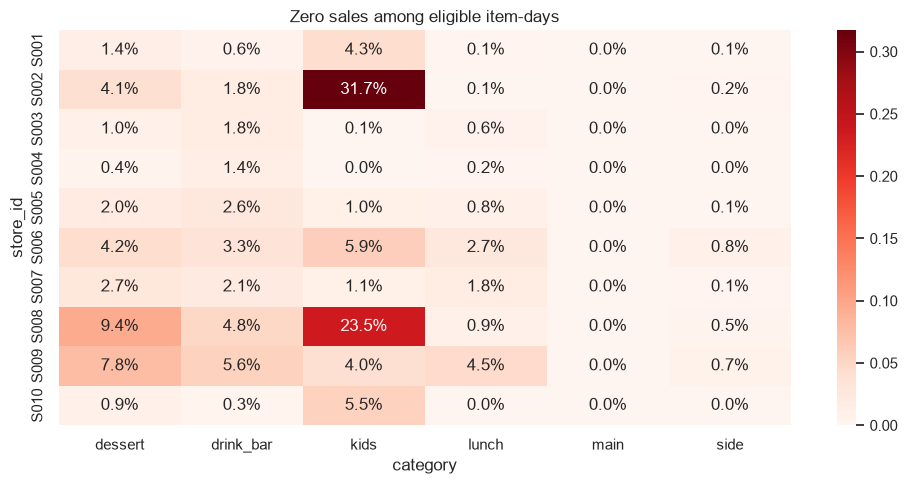

In [3]:
eligible=df[df.state.eq('eligible')].copy()
group=eligible.groupby(['store_id','area_type','category'],observed=True).agg(rows=('zero','size'),zeros=('zero','sum'),items=('item_id','nunique'),sales=('sales_amount','sum')).reset_index()
group['zero_rate']=group.zeros/group.rows
display(group.sort_values('zero_rate',ascending=False).head(25))
print('販売可能でゼロの行:',int(eligible.zero.sum()),'分母:',len(eligible))
display(eligible.groupby(['menu_type','category'],observed=True).agg(rows=('zero','size'),zeros=('zero','sum'),zero_rate=('zero','mean')).sort_values('zeros',ascending=False))
fig,ax=plt.subplots(figsize=(10,5));sns.heatmap(group.pivot(index='store_id',columns='category',values='zero_rate').astype(float),annot=True,fmt='.1%',cmap='Reds',ax=ax);ax.set(title='Zero sales among eligible item-days',xlabel='category');plt.tight_layout();plt.show()

## 曜日・祝日・年ごとの分布
祝日と曜日の頻度は年ごとに異なる。観測値の比率の差から、祝日などの因果効果は分からない。

weekday,0,1,2,3,4,5,6
category,,,,,,,
dessert,0.0379,0.0399,0.0419,0.0391,0.0390,0.0184,0.0202
drink_bar,0.0280,0.0229,0.0295,0.0263,0.0260,0.0175,0.0197
kids,0.0983,0.1076,0.1092,0.1008,0.0990,0.0120,0.0128
lunch,0.0133,0.0137,0.0120,0.0111,0.0120,0.0093,0.0106
main,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
side,0.0030,0.0030,0.0029,0.0028,0.0028,0.0017,0.0012


,year,menu_type,category,rows,zeros,zero_rate
0,2022,collaboration,dessert,756,9,0.0119
1,2022,collaboration,kids,540,43,0.0796
2,2022,collaboration,main,756,0,0.0000
3,2022,collaboration,side,216,0,0.0000
4,2022,core,dessert,43800,1746,0.0399
5,2022,core,drink_bar,7300,179,0.0245
6,2022,core,kids,21900,1453,0.0663
7,2022,core,lunch,43800,398,0.0091
8,2022,core,main,54750,0,0.0000
9,2022,core,side,43800,86,0.0020


rows  zeros  zero_rate
weekday is_holiday                         
0       False       85429   2007     0.0235
        True        13282    119     0.0090
1       False       97468   2246     0.0230
        True         1240      4     0.0032
2       False       95004   2263     0.0238
        True         3100     17     0.0055
3       False       94398   2079     0.0220
        True         3748     33     0.0088
4       False       93103   2069     0.0222
        True         5009     40     0.0080
5       False       94962    739     0.0078
        True         3738     20     0.0054
6       False       94933    789     0.0083
        True         3778     39     0.0103

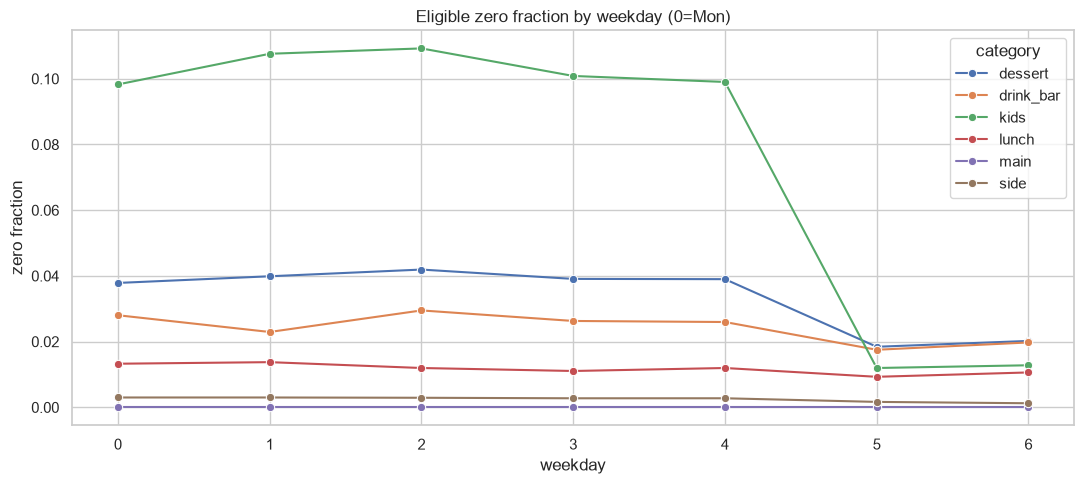

In [4]:
weekday=eligible.groupby(['category','weekday'],observed=True).agg(rows=('zero','size'),zeros=('zero','sum'),zero_rate=('zero','mean')).reset_index()
display(weekday.pivot(index='category',columns='weekday',values='zero_rate'))
annual=eligible.groupby(['year','menu_type','category'],observed=True).agg(rows=('zero','size'),zeros=('zero','sum'),zero_rate=('zero','mean')).reset_index();display(annual)
holiday=eligible.groupby(['weekday','is_holiday'],observed=True).agg(rows=('zero','size'),zeros=('zero','sum'),zero_rate=('zero','mean'));display(holiday)
fig,ax=plt.subplots(figsize=(11,5));sns.lineplot(data=weekday,x='weekday',y='zero_rate',hue='category',marker='o',ax=ax);ax.set(title='Eligible zero fraction by weekday (0=Mon)',ylabel='zero fraction');plt.tight_layout();plt.show()

## 同一店舗の日別売上規模とゼロ率
各店舗の過去の総売上に基づき、店舗内で日を四分位に分けた**事後分析**。同じ日・店舗の他商品の実際の売上を使っているため、2025年の同日予測に使うとリークする。

In [5]:
daily=train.groupby(['date','store_id'],as_index=False).sales_amount.sum().rename(columns={'sales_amount':'store_daily_sales'})
daily['store_rank']=daily.groupby('store_id').store_daily_sales.rank(method='first',pct=True)
daily['sales_quartile']=pd.cut(daily.store_rank,[0,.25,.5,.75,1],labels=['Q1 low','Q2','Q3','Q4 high'],include_lowest=True)
q=eligible.merge(daily[['date','store_id','sales_quartile']],on=['date','store_id'],validate='many_to_one')
qsum=q.groupby(['category','sales_quartile'],observed=True).agg(rows=('zero','size'),zeros=('zero','sum'),zero_rate=('zero','mean')).reset_index()
display(qsum.pivot(index='category',columns='sales_quartile',values='zero_rate'))
print('売上四分位は集計時点で全履歴の実績を使用しているため、予測変数として用いるには再設計が必要。')

売上四分位は集計時点で全履歴の実績を使用しているため、予測変数として用いるには再設計が必要。


sales_quartile,Q1 low,Q2,Q3,Q4 high
category,,,,
dessert,0.0525,0.0397,0.0267,0.0163
drink_bar,0.0349,0.0274,0.0217,0.0131
kids,0.0821,0.0859,0.0802,0.0600
lunch,0.0220,0.0111,0.0090,0.0048
main,0.0000,0.0000,0.0000,0.0000
side,0.0061,0.0022,0.0011,0.0004


## 商品・店舗単位のゼロの集中
販売可能な機会が少ない場合の比率は不安定なため、分母を併記する。単一の商品・店舗でも曜日、施策、客層、季節が変わる。

In [6]:
item=eligible.groupby(['store_id','item_id','item_name','category','menu_type'],observed=True).agg(eligible_days=('zero','size'),zero_days=('zero','sum'),total_sales=('sales_amount','sum')).reset_index();item['zero_rate']=item.zero_days/item.eligible_days
display(item[item.eligible_days>=100].sort_values(['zero_rate','eligible_days'],ascending=[False,False]).head(30))
print('販売可能な日が100日以上あり、毎回ゼロの店舗・商品数:',int(((item.eligible_days>=100)&item.zero_rate.eq(1)).sum()))
print('販売可能だがゼロでも、在庫切れ・欠品等の原因は元データから確定できない。')

販売可能な日が100日以上あり、毎回ゼロの店舗・商品数: 0
販売可能だがゼロでも、在庫切れ・欠品等の原因は元データから確定できない。


,store_id,item_id,item_name,category,menu_type,eligible_days,zero_days,total_sales,zero_rate
114,S002,M031,Kids Curry,kids,core,1096,371,"1,083,015.0000",0.3385
115,S002,M032,Kids Udon Set,kids,core,1096,357,"977,007.0000",0.3257
116,S002,M033,Kids Omelet Rice,kids,core,1096,344,"1,119,678.0000",0.3139
118,S002,M035,Kids Hamburger Plate,kids,core,1096,338,"1,459,779.0000",0.3084
117,S002,M034,Kids Pancake Plate,kids,core,1096,337,"1,239,976.0000",0.3075
113,S002,M030,Kids Plate,kids,core,1096,330,"1,283,717.0000",0.3011
607,S008,M032,Kids Udon Set,kids,core,1096,287,"1,016,834.0000",0.2619
609,S008,M034,Kids Pancake Plate,kids,core,1096,268,"1,280,652.0000",0.2445
606,S008,M031,Kids Curry,kids,core,1096,261,"1,155,727.0000",0.2381
608,S008,M033,Kids Omelet Rice,kids,core,1096,252,"1,207,013.0000",0.2299


## 解釈の注意
- 販売期間・参加店舗による条件外と、販売可能だが売上ゼロのケースを混同しない。
- ゼロの有無は売れ行きだけでなく、営業時間・商品特性・施策・客層・販売機会の違いを含む。明示的な在庫切れログはない。
- 同日の店舗売上や過去全期間の分位は事後情報。特徴量化する場合は基準日以前の履歴だけで作り、時系列検証を行う。